In [24]:
!pip install -q transformers
!pip install -q tensorflow

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

from transformers import AutoTokenizer
from transformers import AutoModelForSequenceClassification

from torch.utils.data import TensorDataset, DataLoader

In [26]:
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded!")
print(df.head())
print("Columns:", df.columns.tolist())

Saving cleaned_amazon_reviews.csv to cleaned_amazon_reviews (3).csv
Dataset loaded!
                                                Text  \
0  I have bought several of the Vitality canned d...   
1  Product arrived labeled as Jumbo Salted Peanut...   
2  This is a confection that has been around a fe...   
3  If you are looking for the secret ingredient i...   
4  Great taffy at a great price.  There was a wid...   

                                      cleaned_review  Score  sentiment_score  \
0  i have bought several of the vitality canned d...      5         0.450000   
1  product arrived labeled as jumbo salted peanut...      1        -0.033333   
2  this is a confection that has been around a fe...      4         0.133571   
3  if you are looking for the secret ingredient i...      2         0.166667   
4  great taffy at a great price there was a wide ...      5         0.483333   

  sentiment_category      fear     anger  anticip     trust  surprise  \
0           Positive  0.0

In [27]:
# Automatically detect columns
text_col = next(
    (c for c in ['review', 'Review', 'Text', 'text', 'reviewText']
     if c in df.columns), None
)

label_col = next(
    (c for c in ['sentiment', 'Sentiment', 'Score',
                 'score', 'rating', 'Rating', 'overall']
     if c in df.columns), None
)

if text_col is None or label_col is None:
    raise ValueError("Check dataset column names printed above!")

df = df[[text_col, label_col]].dropna()
df.columns = ['Review', 'Sentiment']

# Convert ratings into sentiment
if label_col.lower() in ['score', 'rating', 'overall']:
    df['Sentiment'] = df['Sentiment'].apply(
        lambda x: 0 if x <= 2 else (1 if x == 3 else 2)
    )

elif not pd.api.types.is_numeric_dtype(df['Sentiment']):
    labels = {
        'negative': 0,
        'neutral': 1,
        'positive': 2
    }

    df['Sentiment'] = (
        df['Sentiment'].astype(str).str.lower().str.strip()
        .map(labels)
    )

df = df.dropna()
df['Sentiment'] = df['Sentiment'].astype(int)

print(df.head())
print("\nSentiment counts:")
print(df['Sentiment'].value_counts())

                                              Review  Sentiment
0  I have bought several of the Vitality canned d...          2
1  Product arrived labeled as Jumbo Salted Peanut...          0
2  This is a confection that has been around a fe...          2
3  If you are looking for the secret ingredient i...          0
4  Great taffy at a great price.  There was a wid...          2

Sentiment counts:
Sentiment
2    16459
0     3058
1     1738
Name: count, dtype: int64


In [28]:
# Sample up to 1,000 items per sentiment class safely in pandas 2.x
df_sample = df.groupby('Sentiment', group_keys=False).sample(
    n=1000,
    random_state=42,
    replace=False
)

print("Total reviews:", len(df_sample))
print("Sentiment distribution:\n", df_sample['Sentiment'].value_counts())

X = df_sample['Review'].astype(str)
y = df_sample['Sentiment']

Total reviews: 3000
Sentiment distribution:
 Sentiment
0    1000
1    1000
2    1000
Name: count, dtype: int64


In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", len(X_train))
print("Testing:", len(X_test))

Training: 2400
Testing: 600


In [30]:
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=64)
X_test_pad = pad_sequences(X_test_seq, maxlen=64)

lstm_model = Sequential([
    Embedding(5000, 64),
    LSTM(64),
    Dense(3, activation='softmax')
])

lstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train for 5 epochs instead of 1
lstm_model.fit(
    X_train_pad, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

loss, lstm_accuracy = lstm_model.evaluate(X_test_pad, y_test, verbose=0)
print("LSTM Accuracy:", lstm_accuracy)

Epoch 1/5
68/68 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.4009 - loss: 1.0851 - val_accuracy: 0.4500 - val_loss: 1.0473
Epoch 2/5
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.5935 - loss: 0.8809 - val_accuracy: 0.6042 - val_loss: 0.8727
Epoch 3/5
68/68 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.7787 - loss: 0.5690 - val_accuracy: 0.5958 - val_loss: 0.8878
Epoch 4/5
68/68 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.8968 - loss: 0.3211 - val_accuracy: 0.6042 - val_loss: 0.9891
Epoch 5/5
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9398 - loss: 0.1791 - val_accuracy: 0.5750 - val_loss: 1.1363
LSTM Accuracy: 0.5683333277702332


In [31]:
model_name = "google/bert_uncased_L-2_H-128_A-2"

bert_tokenizer = AutoTokenizer.from_pretrained(model_name)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

bert_model.to(device)

print("BERT loaded successfully!")
print("Device:", device)

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT loaded successfully!
Device: cuda


In [32]:
train_enc = bert_tokenizer(
    list(X_train),
    truncation=True,
    padding='max_length',
    max_length=64,
    return_tensors='pt'
)

test_enc = bert_tokenizer(
    list(X_test),
    truncation=True,
    padding='max_length',
    max_length=64,
    return_tensors='pt'
)

train_labels = torch.tensor(
    y_train.to_numpy(), dtype=torch.long
)

test_labels = torch.tensor(
    y_test.to_numpy(), dtype=torch.long
)

In [33]:
train_data = TensorDataset(
    train_enc['input_ids'],
    train_enc['attention_mask'],
    train_labels
)

test_data = TensorDataset(
    test_enc['input_ids'],
    test_enc['attention_mask'],
    test_labels
)

train_loader = DataLoader(
    train_data, batch_size=16, shuffle=True
)

test_loader = DataLoader(
    test_data, batch_size=16
)


In [34]:
optimizer = torch.optim.AdamW(bert_model.parameters(), lr=3e-5)
epochs = 4

for epoch in range(epochs):
    bert_model.train()
    total_loss = 0
    for batch in train_loader:
        input_ids = batch[0].to(device)
        attention_mask = batch[1].to(device)
        labels = batch[2].to(device)

        optimizer.zero_grad()
        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )
        loss = outputs.loss
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch + 1}/{epochs} | Loss: {total_loss / len(train_loader):.4f}")

Epoch 1/4 | Loss: 1.0963
Epoch 2/4 | Loss: 1.0778
Epoch 3/4 | Loss: 1.0467
Epoch 4/4 | Loss: 0.9969


In [35]:
bert_model.eval()

predictions = []
actual = []

with torch.no_grad():

    for batch in test_loader:

        input_ids = batch[0].to(device)
        attention_mask = batch[1].to(device)

        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predicted = torch.argmax(
            outputs.logits, dim=1
        )

        predictions.extend(predicted.cpu().numpy())
        actual.extend(batch[2].numpy())

bert_accuracy = accuracy_score(actual, predictions)

print("BERT Accuracy:", bert_accuracy)

BERT Accuracy: 0.5433333333333333


LSTM Accuracy: 0.5683
BERT Accuracy: 0.5433


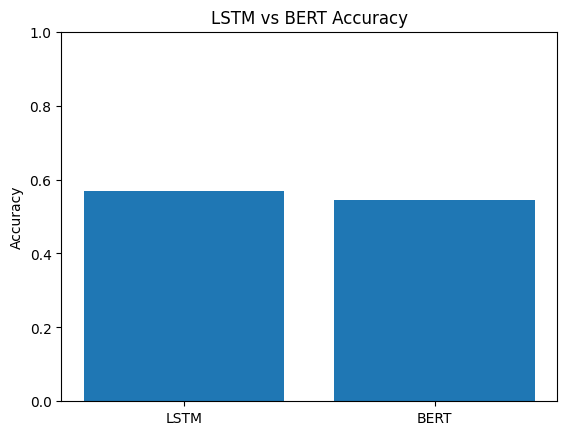

In [36]:
print("LSTM Accuracy:", round(lstm_accuracy, 4))
print("BERT Accuracy:", round(bert_accuracy, 4))

plt.bar(
    ['LSTM', 'BERT'],
    [lstm_accuracy, bert_accuracy]
)

plt.title("LSTM vs BERT Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

In [37]:
print("Sentiment Analysis Completed!")

print("LSTM Accuracy:", round(lstm_accuracy, 4))
print("BERT Accuracy:", round(bert_accuracy, 4))

print("LSTM is our baseline model.")
print("BERT uses transfer learning.")

Sentiment Analysis Completed!
LSTM Accuracy: 0.5683
BERT Accuracy: 0.5433
LSTM is our baseline model.
BERT uses transfer learning.
